**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**01 | HARTH Data Loading and Inspection**

![Data loading and inspection workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/01_workflow.svg)

**Objective:** Load and inspect HARTH v2.0 data using shared data-loading, inspection and signal-visualisation utilities.

**Dataset:** The authors' official HARTH v2.0 GitHub release, using participant `S023.csv`. This version is distinct from the earlier UCI v1.2 release.

**Notebook Scope:** Retrieve and inspect the recording, validate its structure and activity labels, summarise the observed classes and preview unprocessed acceleration signals. No model fitting is performed.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ----------------------- 5. Shared and Study Utilities -----------------------
from core.data_loading import load_data
from core.data_inspection import inspect_data, plot_signal
from harth_data import (
    ACTIVITY_NAMES, SENSOR_COLUMNS,
    ensure_harth_sample, load_harth_subject,
)

# -------------------- 6. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Reusable loading and visualisation functions: ready")
print("Research output directory:", output_dir)

Reusable loading and visualisation functions: ready
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Retrieve the Selected Source Recording**

The pinned `S023.csv` file is downloaded if absent and cached in the Git-ignored `data/raw/harth_v2/` directory.

In [3]:
# ==================== 02. Retrieve Original HARTH Source =====================
data_dir = root / "data" / "raw" / "harth_v2"
csv_path = ensure_harth_sample(data_dir, subject="S023")
print("Source file:", csv_path)


Downloaded 12,061,722 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
Source file: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv


**03. Inspect the Raw Source Table**

The shared `load_data()` and `inspect_data()` utilities report the table structure and missing values before HARTH-specific validation.

In [4]:
# ======================= 03. Inspect Raw Source Table ========================
raw_table = load_data(csv_path)
raw_report = inspect_data(raw_table, name="HARTH raw participant CSV")
print("Raw columns:", list(raw_table.columns))



===== HARTH raw participant CSV =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Raw columns: ['timestamp', 'back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z', 'label']


**04. Validate the HARTH Signal Schema**

The HARTH adapter parses timestamps and checks six acceleration channels (in **g**) and the documented activity codes. The file contains one continuous participant recording.

In [5]:
# ===================== 04. Validate HARTH Signal Schema ======================
data, channel_names = load_harth_subject(csv_path)

summary = inspect_data(data, name="HARTH validated participant")
print("Subject identifier:", csv_path.stem)
print("Accelerometer channels:", channel_names)
print("Sampling rate (source documentation): 50 Hz")


HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH validated participant =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Subject identifier: S023
Accelerometer channels: ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']
Sampling rate (source documentation): 50 Hz


**05. Inspect the Observed Activity-Label Distribution**

Activity counts are calculated directly from `S023.csv` and mapped to the published HARTH activity descriptions.

,label,activity,samples
0,1,Walking,70601
1,2,Running,22391
2,3,Shuffling,2071
3,4,Stairs ascending,3194
4,5,Stairs descending,2291
5,6,Standing,7455
6,7,Sitting,13059
7,8,Lying,16584


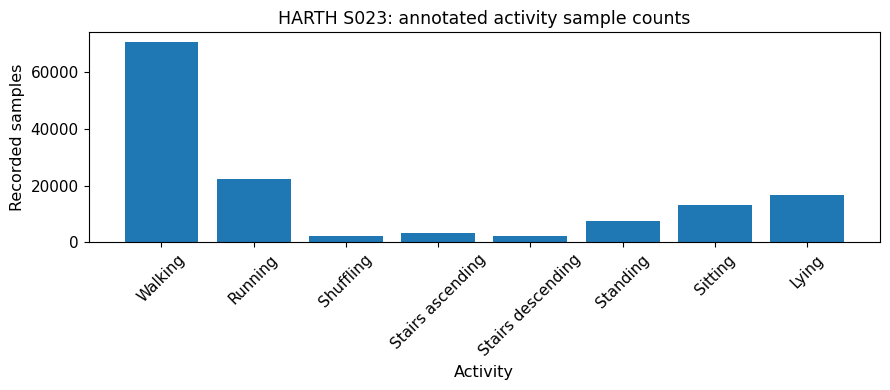

In [6]:
# ==================== 05. Summarise Activity Distribution ====================

# ------------------- 1. Activity Counts and Label Mapping --------------------
activity_counts = data["label"].value_counts().sort_index()
activity_table = pd.DataFrame({
    "label": activity_counts.index,
    "activity": [ACTIVITY_NAMES[int(value)] for value in activity_counts.index],
    "samples": activity_counts.to_numpy(),
})

# ------------------- 2. Activity Support and Visualisation -------------------
display(activity_table)
activity_table.to_csv(output_dir / "01_activity_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(activity_table["activity"], activity_table["samples"])
ax.set(title="HARTH S023: annotated activity sample counts",
       xlabel="Activity", ylabel="Recorded samples")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save_figure(fig, output_dir / "01_activity_distribution.png")
plt.show()


**06. Preview the Original Acceleration Signals**

Up to 250 samples of lower-back acceleration are plotted in **g**, without filtering or scaling.

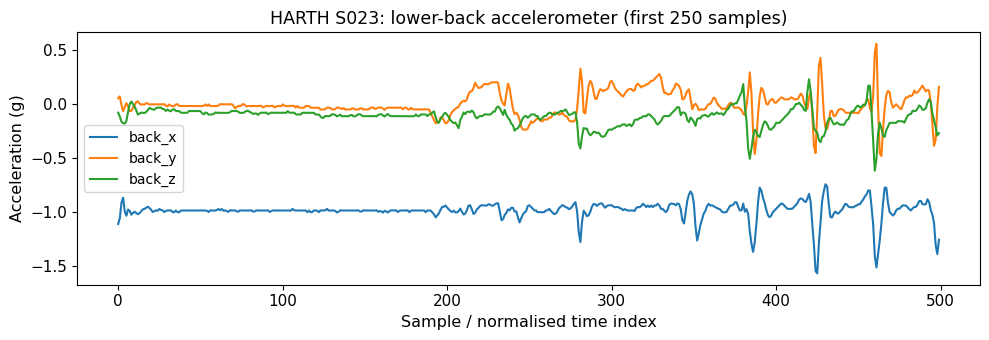

In [ ]:
# ===================== 06. Plot Observed Motion Signals ======================
n_points = min(1000, len(data))
signal = data.loc[:n_points - 1, channel_names[:3]].to_numpy().T
fig = plot_signal(
    signal,
    title="HARTH S023: lower-back accelerometer (first 250 samples)",
    channel_names=channel_names[:3],
)
fig.axes[0].set_ylabel("Acceleration (g)")
save_figure(fig, output_dir / "01_acceleration_signals.png")
plt.show()


**07. Source Data Quality Gate**

The final checks verify required fields, finite acceleration values and the observed sampling interval. This single recording cannot establish performance on unseen participants; participant-disjoint evaluation and model training are addressed in later notebooks.


In [8]:
# ======================= 07. Source Data Quality Gate ========================

# ------------------ 1. Source Integrity and Sampling Checks ------------------
assert len(channel_names) == 6
assert set(["timestamp", "label"]).issubset(data.columns)
assert np.isfinite(data[channel_names].to_numpy()).all()
assert not data.empty
time_delta = data["timestamp"].diff().dt.total_seconds().dropna()

# -------------------------- 2. Quality Gate Summary --------------------------
print("STAGE 01 | SOURCE DATA QUALITY GATE")
print("=" * 72)
print("Number of rows:", len(data))
print("Median observed time interval (s):", time_delta.median())
print("Observed activity codes:", sorted(data["label"].unique().tolist()))
print("Generic reader and inspector reused: YES")
print("Model training performed: NO")
# ------------------ 3. Export Reusable Source Quality Summary ----------------
source_summary = pd.DataFrame([{
    "subject_id": csv_path.stem,
    "source_file": csv_path.name,
    "recorded_samples": int(len(data)),
    "data_columns": int(len(data.columns)),
    "acceleration_channels": int(len(channel_names)),
    "missing_values": int(data.isna().sum().sum()),
    "documented_sampling_frequency_hz": 50,
    "median_observed_sample_interval_s": float(time_delta.median()),
    "observed_activity_classes": int(len(activity_table)),
}])
source_summary.to_csv(output_dir / "01_source_inspection_summary.csv", index=False)
print("Source summary and research figures saved in:", output_dir)

STAGE 01 | SOURCE DATA QUALITY GATE
Number of rows: 137646
Median observed time interval (s): 0.02
Observed activity codes: [1, 2, 3, 4, 5, 6, 7, 8]
Generic reader and inspector reused: YES
Model training performed: NO
Source summary and research figures saved in: /content/human-movement-intelligence/wearable_activity_recognition/output
